
# 03 - Baseline Model Development

## 3.1 Objectives

This notebook investigates the ResNet18 convolutional neural network used as the baseline classifier.

The objectives are to:

- Explain the pretrained ResNet18 architecture and transfer learning.
- Inspect the eight-class classification layer.
- Document the training configuration and hyperparameters.
- Analyse training and validation learning curves.
- Evaluate whether the baseline shows signs of overfitting.
- Establish baseline performance for later model comparisons.


## 3.2 Environment and saved results

In [7]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from enge707.model import build_resnet18

ARTIFACTS = ROOT / "artifacts" / "baseline"

config = json.loads((ARTIFACTS / "config.json").read_text())
metrics = json.loads((ARTIFACTS / "metrics.json").read_text())
history = pd.read_csv(ARTIFACTS / "history.csv")

print("Classes:", config["classes"])
print("Recorded epochs:", len(history))
print("Validation accuracy:", f"{metrics['validation_accuracy']:.2%}")

Classes: ['CatEye', 'CatFace', 'CatMouth', 'CatNose', 'DogEye', 'DogFace', 'DogMouth', 'DogNose']
Recorded epochs: 2
Validation accuracy: 75.35%



## 3.3 ResNet18 Architecture

ResNet18 is a convolutional neural network containing 18 weighted layers. It uses residual connections to help information and gradients pass through the network.

The baseline uses ImageNet-pretrained weights for transfer learning. Its original classification layer is replaced with a fully connected layer that produces eight outputs, corresponding to the eight facial-feature classes.

The following experiment inspects the model architecture without downloading pretrained weights or running training.


In [8]:
model = build_resnet18(
    num_classes=len(config["classes"]),
    pretrained=False,
)

print("Final classification layer:", model.fc)
print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")

Final classification layer: Linear(in_features=512, out_features=8, bias=True)
Total parameters: 11,180,616


## 3.4 Training configuration

In [9]:
settings = [
    "train_samples",
    "validation_samples",
    "epochs",
    "batch_size",
    "learning_rate",
    "weight_decay",
    "early_stopping_patience",
    "seed",
    "device",
]

display(
    pd.DataFrame(
        {"Parameter": settings, "Saved Value": [config.get(key) for key in settings]}
    )
)

,Parameter,Saved Value
0,train_samples,50928
1,validation_samples,12732
2,epochs,2
3,batch_size,64
4,learning_rate,0.001
5,weight_decay,0.0001
6,early_stopping_patience,3
7,seed,42
8,device,cpu


## 3.5 Learning curves

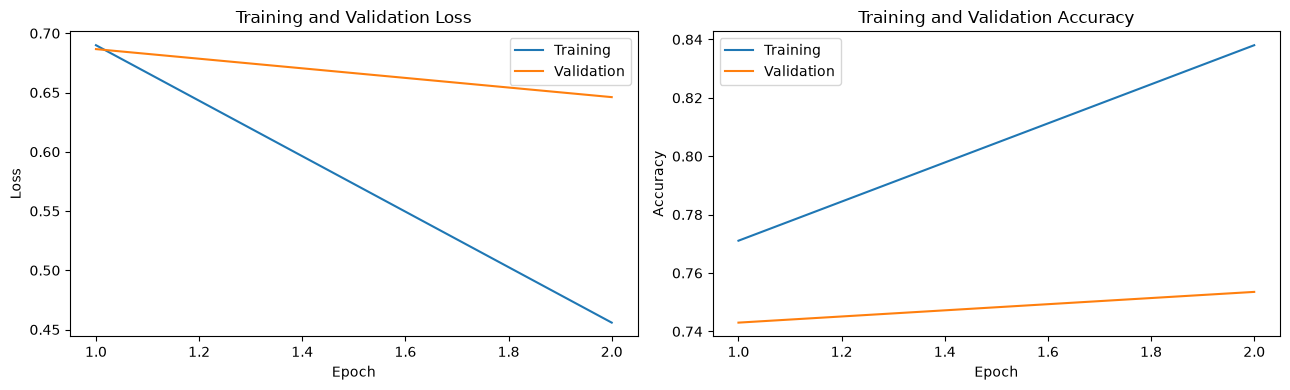

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history["epoch"], history["train_loss"], label="Training")
axes[0].plot(history["epoch"], history["validation_loss"], label="Validation")
axes[0].set(xlabel="Epoch", ylabel="Loss", title="Training and Validation Loss")
axes[0].legend()

axes[1].plot(history["epoch"], history["train_accuracy"], label="Training")
axes[1].plot(history["epoch"], history["validation_accuracy"], label="Validation")
axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Training and Validation Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()


## 3.6 Learning Curve Interpretation

The baseline was trained for two epochs using transfer learning with ResNet18.

Training accuracy increased to approximately 83.8%, while validation accuracy reached 75.35%. Training loss decreased more sharply than validation loss.

The growing difference between training and validation performance suggests that the model is fitting the training data more effectively than unseen validation examples.

However, the short training duration limits conclusions about overfitting. Additional epochs and controlled experiments would be needed to establish whether the validation performance has plateaued.

## 3.7 Findings and Limitations

The ResNet18 baseline successfully performs eight-class facial-feature classification using an adapted fully connected output layer.

The recorded training configuration used a batch size of 64, learning rate of 0.001, random seed 42 and CPU execution.

**Limitations:**

- Only two training epochs were recorded.
- Training and validation accuracy differ noticeably.
- Low-resolution source images may limit feature recognition.
- Validation performance does not guarantee equivalent performance on Kaggle's unseen test images.

The baseline establishes a reference for investigating targeted improvements in Notebook 04.
